# Classificação da avaliação do radiologista (BCSC)

O experimento prevê uma entre seis categorias da avaliação registrada na mamografia a partir de dados tabulares da paciente e do exame. A avaliação do radiologista fornece o rótulo de treino. A confirmação de câncer em até um ano e o tipo de câncer ficam fora da modelagem. As categorias são os rótulos publicados nessa base de rastreamento.

**Fluxo.** Carregar os dados brutos, separar por paciente, comparar cinco algoritmos usando validação cruzada, avaliar os modelos no teste e salvar o pipeline escolhido. O objetivo é educacional. A base tem mamografias de 2005 a 2008 de mulheres de 60 a 89 anos e não contém imagens.

[Dados do BCSC](https://www.bcsc-research.org/datasets/mammography_dataset) · [Aula prática TT002](https://colab.research.google.com/drive/1A5PgU4N_olytqgHK4niUM3y_eiKKyLUW)

In [1]:
from pathlib import Path
from textwrap import fill

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

## 1. Atributos e classes

As entradas são idade, densidade mamária, tipo de mamografia, disponibilidade de imagens anteriores, histórico familiar, terapia hormonal, mamografia prévia e biópsia anterior. A densidade mamária representa a composição da mama, com quatro categorias próprias. Para usar o pipeline, ela precisa estar disponível no momento da previsão.

O identificador da paciente serve para agrupar seus exames na divisão. O IMC fica fora, seguindo o pré-processamento exploratório, pois 58% dos valores estão ausentes. O treino começa pelo CSV bruto para que o preenchimento de ausências possa ser ajustado usando apenas a partição de treino de cada rodada.

In [2]:
arquivo = Path("dataset/breast_cancer_screening_bcsc.csv")
if not arquivo.is_file():
    arquivo = Path("..") / arquivo

url_bcsc = (
    "https://raw.githubusercontent.com/arthurMalveste/"
    "Breast-Cancer-Analysis-and-Classification/e1f23dd7904492be4ec9bfc49e2fbbbc45b4386d/"
    "dataset/breast_cancer_screening_bcsc.csv"
)
dados = pd.read_csv(arquivo if arquivo.is_file() else url_bcsc)

idade = "Age_At_The_Time_Of_Mammography"
categoricas = [
    "Patients_BI_RADS_Breast_Density",
    "Is_Film_Or_Digital_Mammogram",
    "Comparison_Mammogram_From_Mammography",
    "Family_History_Of_Breast_Cancer",
    "Current_Use_Of_Hormone_Therapy",
    "Binary_Indicator",
    "History_Of_Breast_Biopsy",
]
entradas = [idade, *categoricas]
nomes_classes = {
    "Negative": "Negativo",
    "Benign findings": "Achados benignos",
    "Probably benign": "Provavelmente benigno",
    "Needs additional imaging": "Precisa de imagens adicionais",
    "Suspicious abnormality": "Anormalidade suspeita",
    "Highly suggestive of malignancy": "Altamente sugestivo de malignidade",
}
classes = list(nomes_classes)
X = dados[entradas]
y = dados["Radiologists_Assessment"]
pacientes = dados["Patients_Study_ID"]
assert set(y.unique()) == set(classes) and pacientes.notna().all()

contagens = y.value_counts().reindex(classes)
resumo = pd.DataFrame({
    "Exames": contagens,
    "Participação (%)": (100 * contagens / len(y)).round(3),
}).rename(index=nomes_classes)
display(resumo)

,Exames,Participação (%)
Radiologists_Assessment,,
Negativo,26031,65.081
Achados benignos,10717,26.794
Provavelmente benigno,139,0.348
Precisa de imagens adicionais,3049,7.623
Anormalidade suspeita,57,0.143
Altamente sugestivo de malignidade,5,0.013


**Interpretação.** A classe Negativo representa cerca de 65% da amostra. A categoria Altamente sugestivo de malignidade aparece apenas cinco vezes. Com esse suporte, a avaliação dessa classe será muito sensível ao resultado de cada exame.

## 2. Divisão por paciente

Reservamos aproximadamente 20% da base para teste e usamos quatro partições de validação cruzada no restante. A estratificação procura manter as proporções das classes. O agrupamento impede que exames da mesma paciente apareçam simultaneamente no treino e no teste ou no treino e na validação de uma rodada.

In [3]:
semente = 42
divisao_teste = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semente)
treino, teste = next(divisao_teste.split(X, y, pacientes))
X_treino, X_teste = X.iloc[treino], X.iloc[teste]
y_treino, y_teste = y.iloc[treino], y.iloc[teste]
pacientes_treino, pacientes_teste = pacientes.iloc[treino], pacientes.iloc[teste]
assert set(pacientes_treino).isdisjoint(pacientes_teste)
assert set(y_treino) == set(y_teste) == set(classes)

divisao_validacao = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=semente)
particoes = list(divisao_validacao.split(X_treino, y_treino, pacientes_treino))
for ajuste, validacao in particoes:
    assert set(pacientes_treino.iloc[ajuste]).isdisjoint(pacientes_treino.iloc[validacao])
    assert set(y_treino.iloc[ajuste]) == set(y_treino.iloc[validacao]) == set(classes)

display(pd.DataFrame({
    "Treino (exames)": y_treino.value_counts(),
    "Teste (exames)": y_teste.value_counts(),
}).reindex(classes).rename(index=nomes_classes))

,Treino (exames),Teste (exames)
Radiologists_Assessment,,
Negativo,20824,5207
Achados benignos,8574,2143
Provavelmente benigno,111,28
Precisa de imagens adicionais,2439,610
Anormalidade suspeita,46,11
Altamente sugestivo de malignidade,4,1


## 3. Treinamento e escolha do modelo

Comparamos regressão logística, árvore de decisão, floresta aleatória, KNN e Naive Bayes gaussiano. Regressão, árvore e floresta recebem pesos de classe para dar mais importância aos exemplos raros. KNN e Naive Bayes usam seus ajustes de referência. O classificador que sempre prevê a classe mais frequente é a linha de base.

Cada pipeline aprende a mediana e a escala da idade, preenche os campos categóricos com a moda e codifica as categorias em colunas binárias. Cada etapa aprende seus parâmetros no treino da rodada. A escolha usa **F1 macro médio na validação cruzada**, que dá o mesmo peso às seis classes. O teste fica reservado para a comparação final.

In [4]:
def construir_pipeline(classificador):
    preprocessamento = ColumnTransformer([
        ("idade", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), [idade]),
        ("categorias", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ), categoricas),
    ])
    return make_pipeline(preprocessamento, classificador)


linha_base = "Classe majoritária"
algoritmos = {
    linha_base: DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Árvore de decisão": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=25, class_weight="balanced", random_state=semente,
    ),
    "Floresta aleatória": RandomForestClassifier(
        n_estimators=100, min_samples_leaf=10, class_weight="balanced",
        random_state=semente, n_jobs=2,
    ),
    "KNN": KNeighborsClassifier(n_neighbors=35),
    "Naive Bayes gaussiano": GaussianNB(),
}

modelos = {}
resultados_validacao = {}
for nome, classificador in algoritmos.items():
    modelo = construir_pipeline(classificador)
    f1_validacao = cross_val_score(modelo, X_treino, y_treino, cv=particoes, scoring="f1_macro")
    resultados_validacao[nome] = {
        "F1 macro médio": f1_validacao.mean(),
        "Desvio entre partições": f1_validacao.std(),
    }
    modelos[nome] = modelo.fit(X_treino, y_treino)

validacao = pd.DataFrame.from_dict(resultados_validacao, orient="index")
escolhido = validacao.drop(index=linha_base)["F1 macro médio"].idxmax()
display(validacao.sort_values("F1 macro médio", ascending=False).round(4))
print(f"Selecionado pela validação cruzada: {escolhido}")

,F1 macro médio,Desvio entre partições
Floresta aleatória,0.1712,0.0030
KNN,0.1608,0.0018
Regressão logística,0.1391,0.0102
Classe majoritária,0.1314,0.0000
Árvore de decisão,0.1150,0.0096
Naive Bayes gaussiano,0.0435,0.0125


Selecionado pela validação cruzada: Floresta aleatória


## 4. Avaliação no teste

- **Acurácia** mede a fração total de exames classificados corretamente. Pode subir mesmo quando o modelo erra as classes raras.
- **Precisão macro** calcula, para cada classe, a proporção de acertos entre as previsões daquela classe e tira a média simples. Classes sem previsões recebem zero.
- **Recall macro** calcula a proporção de exames identificados dentro de cada classe real e tira a média simples. Nesta avaliação, equivale à acurácia balanceada.
- **F1 macro** calcula a média dos F1 por classe. O F1 combina precisão e recall, penalizando quando um dos dois é baixo.

,Acurácia,Precisão macro,Recall macro,F1 macro
Classe majoritária,0.6509,0.1085,0.1667,0.1314
Regressão logística,0.2006,0.1976,0.1473,0.1239
Árvore de decisão,0.2006,0.1994,0.2781,0.1039
Floresta aleatória,0.3626,0.1967,0.2072,0.1666
KNN,0.6399,0.1749,0.1747,0.1580
Naive Bayes gaussiano,0.0640,0.2104,0.0948,0.0570


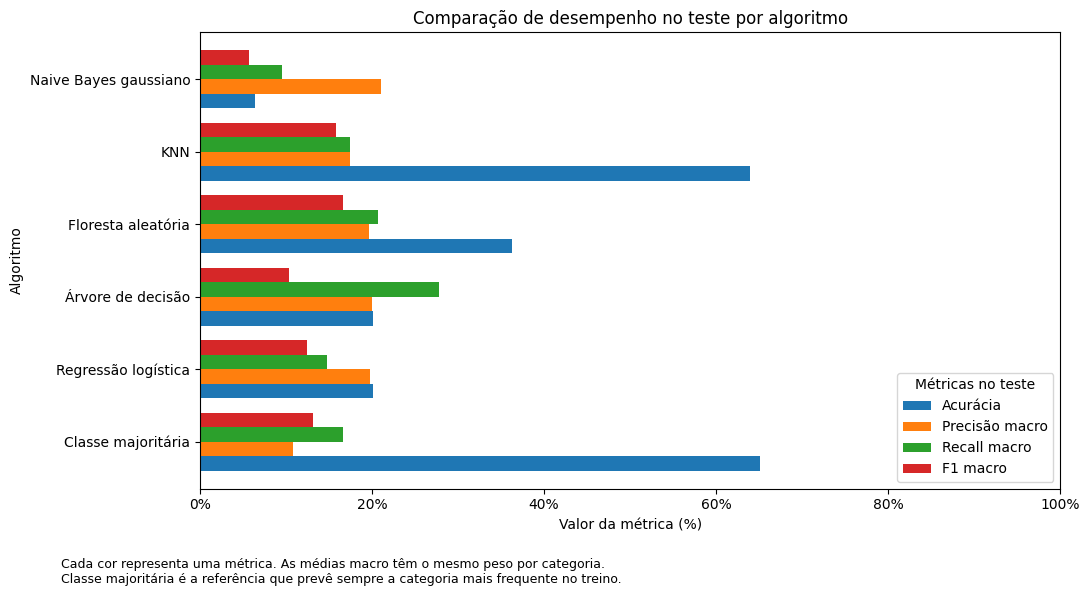

In [5]:
previsoes = {nome: modelo.predict(X_teste) for nome, modelo in modelos.items()}
metricas = pd.DataFrame.from_dict({
    nome: {
        "Acurácia": accuracy_score(y_teste, previsto),
        "Precisão macro": precision_score(
            y_teste, previsto, labels=classes, average="macro", zero_division=0,
        ),
        "Recall macro": balanced_accuracy_score(y_teste, previsto),
        "F1 macro": f1_score(y_teste, previsto, labels=classes, average="macro", zero_division=0),
    }
    for nome, previsto in previsoes.items()
}, orient="index")
display(metricas.round(4))

ax = metricas.plot.barh(figsize=(11, 6), width=0.8, xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Comparação de desempenho no teste por algoritmo")
ax.set_xlabel("Valor da métrica (%)")
ax.set_ylabel("Algoritmo")
ax.legend(title="Métricas no teste", loc="lower right")
ax.figure.text(
    0.06, 0.02,
    "Cada cor representa uma métrica. As médias macro têm o mesmo peso por categoria.\n"
    "Classe majoritária é a referência que prevê sempre a categoria mais frequente no treino.",
    fontsize=9,
)
ax.figure.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

,Precisão,Recall,F1,Exames no teste
Negativo,0.7249,0.4008,0.5162,5207
Achados benignos,0.3441,0.3075,0.3248,2143
Provavelmente benigno,0.0033,0.1071,0.0064,28
Precisa de imagens adicionais,0.1049,0.2459,0.1471,610
Anormalidade suspeita,0.0027,0.1818,0.0054,11
Altamente sugestivo de malignidade,0.0000,0.0000,0.0000,1


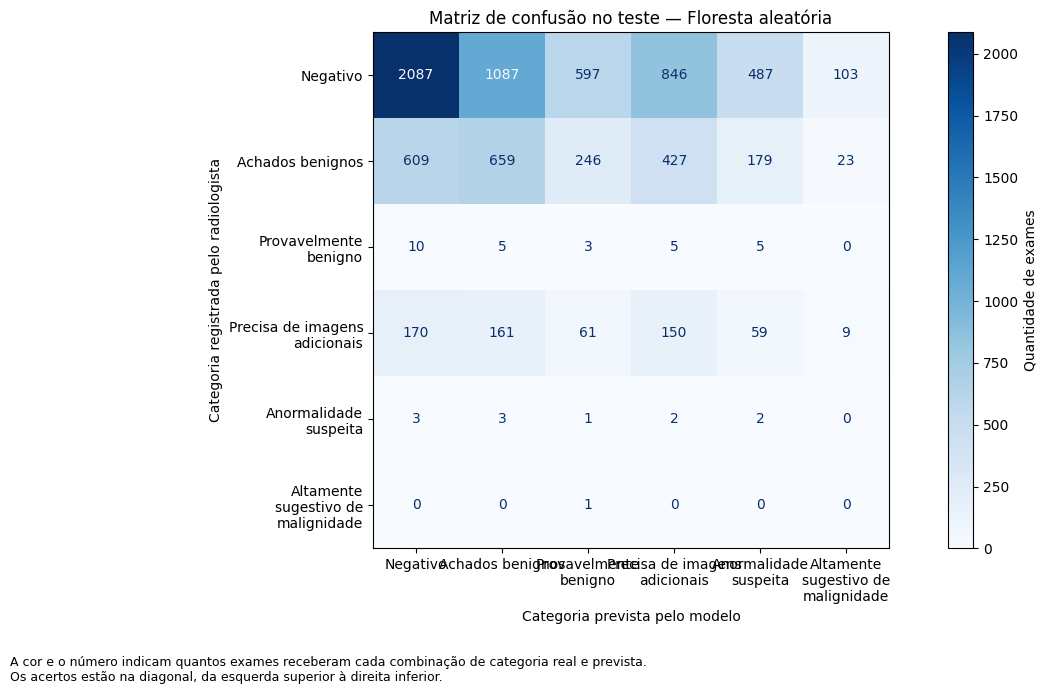

In [6]:
relatorio = pd.DataFrame(classification_report(
    y_teste, previsoes[escolhido], labels=classes, target_names=list(nomes_classes.values()),
    zero_division=0, output_dict=True,
)).T.loc[list(nomes_classes.values())]
relatorio = relatorio.rename(columns={
    "precision": "Precisão", "recall": "Recall", "f1-score": "F1", "support": "Exames no teste",
})
relatorio["Exames no teste"] = relatorio["Exames no teste"].astype(int)
display(relatorio.round(4))

fig, ax = plt.subplots(figsize=(12, 7))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes[escolhido], labels=classes,
    display_labels=[fill(nomes_classes[classe], width=18) for classe in classes],
    cmap="Blues", values_format="d", xticks_rotation=0, ax=ax,
)
ax.set_title(f"Matriz de confusão no teste — {escolhido}")
ax.set_ylabel("Categoria registrada pelo radiologista")
ax.set_xlabel("Categoria prevista pelo modelo")
fig.axes[-1].set_ylabel("Quantidade de exames")
fig.text(
    0.06, 0.02,
    "A cor e o número indicam quantos exames receberam cada combinação de categoria real e prevista.\n"
    "Os acertos estão na diagonal, da esquerda superior à direita inferior.",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

In [7]:
teste_escolhido = metricas.loc[escolhido]
teste_base = metricas.loc[linha_base]
diferenca_f1 = teste_escolhido["F1 macro"] - teste_base["F1 macro"]
print(f"{escolhido}: acurácia de {teste_escolhido['Acurácia']:.1%} e F1 macro de {teste_escolhido['F1 macro']:.1%}.")
print(f"Linha de base: acurácia de {teste_base['Acurácia']:.1%} e F1 macro de {teste_base['F1 macro']:.1%}.")
print(f"Diferença de F1 macro em relação à linha de base: {diferenca_f1 * 100:+.1f} pontos percentuais.")
for categoria in ("Suspicious abnormality", "Highly suggestive of malignancy"):
    reais = y_teste.eq(categoria)
    acertos = (previsoes[escolhido][reais.to_numpy()] == categoria).sum()
    print(f"{nomes_classes[categoria]}: {acertos} de {reais.sum()} exames identificados.")

Floresta aleatória: acurácia de 36.3% e F1 macro de 16.7%.
Linha de base: acurácia de 65.1% e F1 macro de 13.1%.
Diferença de F1 macro em relação à linha de base: +3.5 pontos percentuais.
Anormalidade suspeita: 2 de 11 exames identificados.
Altamente sugestivo de malignidade: 0 de 1 exames identificados.


**Interpretação.** Na execução de referência, a floresta aleatória obteve 36,26% de acurácia e 16,66% de F1 macro no teste. A regra majoritária teve 65,09% de acurácia e 13,14% de F1 macro. O F1 macro subiu 3,52 pontos percentuais porque a floresta identificou parte das categorias minoritárias, mas o recall macro ficou em 20,72%. A árvore de decisão alcançou recall macro maior (27,81%) e F1 macro menor (10,39%), o que evidencia o custo em precisão.

Para anormalidade suspeita, a floresta acertou 2 dos 11 exames da classe e apenas 0,27% das previsões dessa categoria estavam corretas. Para a classe altamente sugestiva, errou o único exame de teste. Mesmo um acerto nesse exame seria evidência insuficiente de generalização. Os resultados mostram viabilidade como experimento educacional e desempenho baixo para distinguir as seis avaliações usando apenas atributos tabulares.

## 5. Salvar e testar uma previsão

O arquivo contém o pipeline ajustado no treino, as colunas esperadas, os nomes das classes e a versão do scikit-learn. O código abaixo recarrega o arquivo e prevê uma categoria para um exemplo fictício. Os valores de `predict_proba` são estimativas do classificador por categoria e podem sofrer efeito dos pesos de classe. Eles se referem à avaliação do radiologista.

In [8]:
raiz = Path("..") if Path("../dataset").is_dir() else Path(".")
destino = raiz / "modelos" / "avaliacao-radiologista.joblib"
destino.parent.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "pipeline": modelos[escolhido],
    "algoritmo": escolhido,
    "entradas": entradas,
    "nomes_classes": nomes_classes,
    "versao_sklearn": sklearn.__version__,
}, destino, compress=3)

salvo = joblib.load(destino)
exame_ficticio = pd.DataFrame([{
    "Age_At_The_Time_Of_Mammography": 68,
    "Patients_BI_RADS_Breast_Density": "Scattered fibroglandular densities",
    "Is_Film_Or_Digital_Mammogram": True,
    "Comparison_Mammogram_From_Mammography": "Yes",
    "Family_History_Of_Breast_Cancer": "No",
    "Current_Use_Of_Hormone_Therapy": "No",
    "Binary_Indicator": "Yes",
    "History_Of_Breast_Biopsy": "No",
}], columns=salvo["entradas"])

pipeline = salvo["pipeline"]
categoria_prevista = pipeline.predict(exame_ficticio)[0]
estimativas = pd.Series(
    pipeline.predict_proba(exame_ficticio)[0], index=pipeline.classes_,
    name="Estimativa por categoria (%)",
).reindex(classes).mul(100)
display(estimativas.rename(index=salvo["nomes_classes"]).round(2).to_frame())
print(f"Categoria prevista: {salvo['nomes_classes'][categoria_prevista]}")
print(f"Arquivo salvo em {destino}")

,Estimativa por categoria (%)
Negativo,44.20
Achados benignos,31.97
Provavelmente benigno,0.00
Precisa de imagens adicionais,23.83
Anormalidade suspeita,0.00
Altamente sugestivo de malignidade,0.00


Categoria prevista: Negativo
Arquivo salvo em modelos/avaliacao-radiologista.joblib
